Load the breast cancer dataset and make a reproducible stratified train/test split.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.metrics import RocCurveDisplay

cancer = load_breast_cancer()
X, y = cancer.data, cancer.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Dataset shape:", X.shape)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Class names (target 0, target 1):", cancer.target_names)

Dataset shape: (569, 30)
Training samples: 455
Test samples: 114
Class names (target 0, target 1): ['malignant' 'benign']


Train a random forest and print its confusion matrix and classification report.

In [2]:
forest = RandomForestClassifier(random_state=42)
forest.fit(X_train, y_train)
y_pred = forest.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix (rows=true, columns=predicted):\n", cm)
print("\nClassification report:\n", classification_report(y_test, y_pred, target_names=cancer.target_names))

Confusion matrix (rows=true, columns=predicted):
 [[39  3]
 [ 2 70]]

Classification report:
               precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



Visualize the random forest confusion matrix with its class labels.

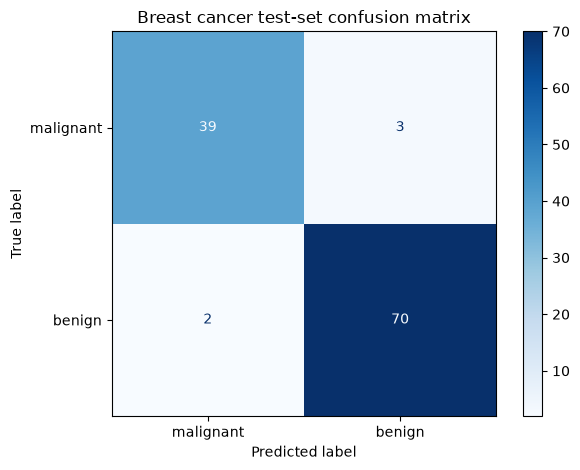

In [3]:
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cancer.target_names).plot(cmap="Blues")
plt.title("Breast cancer test-set confusion matrix")
plt.tight_layout()
plt.show()

Calculate ROC AUC from predicted probabilities and plot the ROC curve with a chance baseline.

ROC AUC: 0.9937


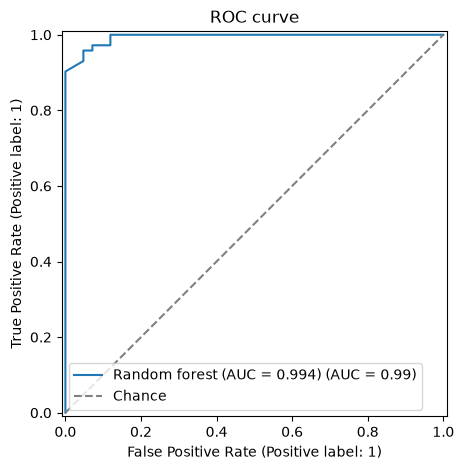

In [4]:
y_probability = forest.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_probability)
print(f"ROC AUC: {auc:.4f}")

ax = plt.gca()
RocCurveDisplay.from_predictions(y_test, y_probability, name=f"Random forest (AUC = {auc:.3f})", ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.legend()
plt.title("ROC curve")
plt.tight_layout()
plt.show()

Calculate positive-class precision, recall, and F1 from TP, FP, and FN, then check sklearn's results.

In [5]:
tn, fp, fn, tp = cm.ravel()
manual_precision = tp / (tp + fp) if tp + fp else 0.0
manual_recall = tp / (tp + fn) if tp + fn else 0.0
manual_f1 = (2 * manual_precision * manual_recall / (manual_precision + manual_recall)
             if manual_precision + manual_recall else 0.0)

sklearn_precision = precision_score(y_test, y_pred, pos_label=1)
sklearn_recall = recall_score(y_test, y_pred, pos_label=1)
sklearn_f1 = f1_score(y_test, y_pred, pos_label=1)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Positive class ({cancer.target_names[1]}) manual: precision={manual_precision:.4f}, recall={manual_recall:.4f}, F1={manual_f1:.4f}")
print(f"Positive class sklearn:            precision={sklearn_precision:.4f}, recall={sklearn_recall:.4f}, F1={sklearn_f1:.4f}")
assert np.isclose(manual_precision, sklearn_precision)
assert np.isclose(manual_recall, sklearn_recall)
assert np.isclose(manual_f1, sklearn_f1)
print("Manual metrics match sklearn.")

TN=39, FP=3, FN=2, TP=70
Positive class (benign) manual: precision=0.9589, recall=0.9722, F1=0.9655
Positive class sklearn:            precision=0.9589, recall=0.9722, F1=0.9655
Manual metrics match sklearn.


Compare positive-class precision and recall at four probability thresholds.

 Threshold Precision Recall
       0.3    0.9342 0.9861
       0.5    0.9589 0.9722
       0.7    1.0000 0.8889
       0.9    1.0000 0.7500


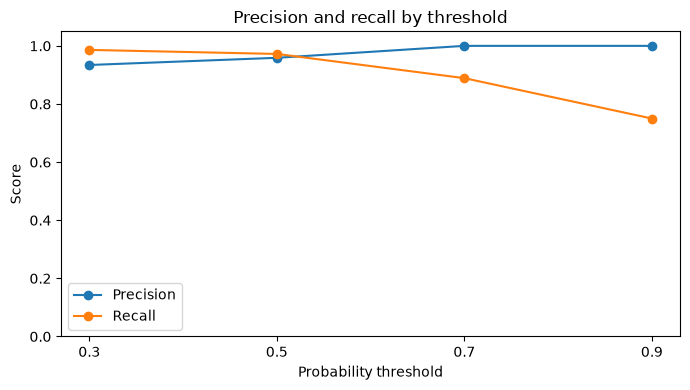

In [6]:
thresholds = [0.3, 0.5, 0.7, 0.9]
threshold_rows = []
for threshold in thresholds:
    threshold_pred = (y_probability >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, threshold_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, threshold_pred, pos_label=1, zero_division=0),
    })

threshold_metrics = pd.DataFrame(threshold_rows)
print(threshold_metrics.to_string(index=False, formatters={
    "Precision": "{:.4f}".format,
    "Recall": "{:.4f}".format,
}))
plt.figure(figsize=(7, 4))
plt.plot(threshold_metrics["Threshold"], threshold_metrics["Precision"], marker="o", label="Precision")
plt.plot(threshold_metrics["Threshold"], threshold_metrics["Recall"], marker="o", label="Recall")
plt.xlabel("Probability threshold")
plt.ylabel("Score")
plt.title("Precision and recall by threshold")
plt.xticks(thresholds)
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

Create a reproducible synthetic dataset with a small minority class and split it for evaluation.

In [7]:
X_imbalance, y_imbalance = make_classification(
    n_samples=5000, weights=[0.95, 0.05], random_state=42
)
X_imb_train, X_imb_test, y_imb_train, y_imb_test = train_test_split(
    X_imbalance, y_imbalance, test_size=0.2, random_state=42, stratify=y_imbalance
)
print("Synthetic class counts:", np.bincount(y_imbalance))

Synthetic class counts: [4724  276]


Compare majority-class dummy and random forest accuracy, recall, and F1 on the same test split.

In [8]:
imbalance_models = {
    "Most-frequent dummy": DummyClassifier(strategy="most_frequent"),
    "Random forest": RandomForestClassifier(random_state=42),
}
imbalance_rows = []
for model_name, model in imbalance_models.items():
    model.fit(X_imb_train, y_imb_train)
    prediction = model.predict(X_imb_test)
    imbalance_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_imb_test, prediction),
        "Recall": recall_score(y_imb_test, prediction, zero_division=0),
        "F1": f1_score(y_imb_test, prediction, zero_division=0),
    })

imbalance_metrics = pd.DataFrame(imbalance_rows)
print(imbalance_metrics.to_string(index=False, formatters={
    "Accuracy": "{:.4f}".format,
    "Recall": "{:.4f}".format,
    "F1": "{:.4f}".format,
}))

              Model Accuracy Recall     F1
Most-frequent dummy   0.9450 0.0000 0.0000
      Random forest   0.9550 0.4000 0.4944
